# RetailPulse: Customer Analytics & Demand Forecasting
**Data:** 641,798 sales rows (Jan 2021 to Oct 2025), 5,000 customers, 200 products, 50 stores in 3 UAE cities (Dubai, Abu Dhabi, Sharjah), 5 sales channels.

**Sections:** 1. Cleaning, 2. Profit and EDA, 3. Demand forecasting, 4. Inventory, 5. Customer segmentation, 6. Churn, 7. Export for the dashboard, 8. Experiment tracking (MLflow).

In [1]:
# imported the library 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load the dataset
#load the customer dataset
cdf=pd.read_csv('bm_customers.csv')
#load the sales dataset
sdf=pd.read_csv('bm_sales.csv')
#load the product dataset
pdf=pd.read_csv('bm_skus.csv')
#load the store dataset 
stdf=pd.read_csv('bm_stores.csv')

In [3]:
#inspect the data set os customer
cdf.head()

,cust_id,age,gender,city,loyalty_segment,preferred_channel,registration_date
0,1,50,Male,Sharjah,Silver,MobileApp,2024-06-29
1,2,20,Female,Abu Dhabi,Gold,Store,2024-12-03
2,3,55,Male,Dubai,Gold,Website,2023-09-18
3,4,25,Male,Abu Dhabi,Platinum,Store,2022-01-02
4,5,20,Female,Abu Dhabi,Silver,MobileApp,2021-09-13


In [4]:
cdf.shape

(5000, 7)

In [5]:
cdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   cust_id            5000 non-null   int64
 1   age                5000 non-null   int64
 2   gender             5000 non-null   str  
 3   city               5000 non-null   str  
 4   loyalty_segment    5000 non-null   str  
 5   preferred_channel  5000 non-null   str  
 6   registration_date  5000 non-null   str  
dtypes: int64(2), str(5)
memory usage: 437.1 KB


In [6]:
cdf.describe()

,cust_id,age
count,5000.000000,5000.000000
mean,2500.500000,31.097800
std,1443.520003,10.746689
min,1.000000,18.000000
25%,1250.750000,20.000000
50%,2500.500000,30.000000
75%,3750.250000,35.000000
max,5000.000000,60.000000


In [7]:
cdf.columns

Index(['cust_id', 'age', 'gender', 'city', 'loyalty_segment',
       'preferred_channel', 'registration_date'],
      dtype='str')

In [8]:
cdf.rename(columns={'cust_id':'customer_id','city':'customer_city'},inplace=True)

In [9]:
cdf.columns

Index(['customer_id', 'age', 'gender', 'customer_city', 'loyalty_segment',
       'preferred_channel', 'registration_date'],
      dtype='str')

## 1. Data cleaning
- Customers, products and stores have no missing values or duplicates.
- Sales: 45 exact duplicate rows were dropped (negligible, and there is no transaction ID to confirm they were errors).
- 159,821 sales (about 25%) have no `customer_id`. These are guest purchases. They are kept for sales analysis and handled separately for any customer modelling.
- After merging sales with products, customers and stores, the row count still equals the sales row count, so the joins did not duplicate any sales.

In [10]:
#data cleaning
cdf.isna().sum()

customer_id          0
age                  0
gender               0
customer_city        0
loyalty_segment      0
preferred_channel    0
registration_date    0
dtype: int64

In [11]:
cdf.duplicated().sum()

np.int64(0)

In [12]:
cdf['registration_date']=pd.to_datetime(cdf['registration_date'])

In [13]:
cdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customer_id        5000 non-null   int64         
 1   age                5000 non-null   int64         
 2   gender             5000 non-null   str           
 3   customer_city      5000 non-null   str           
 4   loyalty_segment    5000 non-null   str           
 5   preferred_channel  5000 non-null   str           
 6   registration_date  5000 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(2), str(4)
memory usage: 388.2 KB


In [14]:
# for sales data set
sdf.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [15]:
sdf.shape

(641843, 9)

In [16]:
sdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          641843 non-null  str    
 1   store_id      641843 non-null  int64  
 2   sku_id        641843 non-null  int64  
 3   customer_id   482022 non-null  float64
 4   quantity      641843 non-null  int64  
 5   unit_price    641843 non-null  float64
 6   total_value   641843 non-null  float64
 7   channel       641843 non-null  str    
 8   discount_pct  641843 non-null  float64
dtypes: float64(4), int64(3), str(2)
memory usage: 54.2 MB


In [17]:
sdf.columns

Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price',
       'total_value', 'channel', 'discount_pct'],
      dtype='str')

In [18]:
sdf.rename(columns={'sku_id':'product_id','unit_price':'sales_price','discount_pct':'discount_percentage'},inplace=True)

In [19]:
sdf.columns

Index(['date', 'store_id', 'product_id', 'customer_id', 'quantity',
       'sales_price', 'total_value', 'channel', 'discount_percentage'],
      dtype='str')

In [20]:
sdf.describe()

,store_id,product_id,customer_id,quantity,sales_price,total_value,discount_percentage
count,641843.000000,641843.000000,482022.000000,641843.000000,641843.000000,641843.000000,641843.000000
mean,25.491081,1100.547835,2504.986828,2.613120,44.109242,114.069845,5.411316
std,14.437269,57.684158,1442.340254,1.481563,48.984342,157.206354,8.664765
min,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000
25%,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000
50%,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000
75%,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000
max,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000


In [21]:
sdf.isna().sum()

date                        0
store_id                    0
product_id                  0
customer_id            159821
quantity                    0
sales_price                 0
total_value                 0
channel                     0
discount_percentage         0
dtype: int64

In [22]:
sdf.duplicated().sum()

np.int64(45)

In [23]:
sdf['date']=pd.to_datetime(sdf['date'])


In [24]:
sdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 641843 non-null  datetime64[us]
 1   store_id             641843 non-null  int64         
 2   product_id           641843 non-null  int64         
 3   customer_id          482022 non-null  float64       
 4   quantity             641843 non-null  int64         
 5   sales_price          641843 non-null  float64       
 6   total_value          641843 non-null  float64       
 7   channel              641843 non-null  str           
 8   discount_percentage  641843 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(3), str(1)
memory usage: 48.1 MB


In [25]:
#for sales
sdf[sdf.duplicated(keep=False)]['customer_id'].isna().sum()

np.int64(87)

In [26]:
sdf=sdf.drop_duplicates()

In [27]:
sdf.duplicated().sum()

np.int64(0)

In [28]:
pdf.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


In [29]:
pdf.shape

(200, 7)

In [30]:
pdf.columns

Index(['sku_id', 'sku_name', 'category', 'subcategory', 'unit_price',
       'cost_price', 'brand'],
      dtype='str')

In [31]:
pdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sku_id       200 non-null    int64  
 1   sku_name     200 non-null    str    
 2   category     200 non-null    str    
 3   subcategory  200 non-null    str    
 4   unit_price   200 non-null    float64
 5   cost_price   200 non-null    float64
 6   brand        200 non-null    str    
dtypes: float64(2), int64(1), str(4)
memory usage: 20.4 KB


In [32]:
pdf.describe()

,sku_id,unit_price,cost_price
count,200.000000,200.000000,200.000000
mean,1100.500000,46.682300,31.060100
std,57.879185,51.590508,34.435869
min,1001.000000,2.610000,1.680000
25%,1050.750000,15.242500,10.065000
50%,1100.500000,25.910000,17.115000
75%,1150.250000,51.270000,34.322500
max,1200.000000,245.380000,187.670000


In [33]:
pdf.isna().sum()

sku_id         0
sku_name       0
category       0
subcategory    0
unit_price     0
cost_price     0
brand          0
dtype: int64

In [34]:
pdf.duplicated().sum()

np.int64(0)

In [35]:
pdf.rename(columns={'sku_id':'product_id','sku_name':'product_name','unit_price':'list_price'},inplace=True)

In [36]:
pdf.columns

Index(['product_id', 'product_name', 'category', 'subcategory', 'list_price',
       'cost_price', 'brand'],
      dtype='str')

In [37]:
stdf.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


In [38]:
stdf.shape

(50, 5)

In [39]:
stdf.columns

Index(['store_id', 'store_name', 'city', 'store_type', 'opening_date'], dtype='str')

In [40]:
stdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   store_id      50 non-null     int64
 1   store_name    50 non-null     str  
 2   city          50 non-null     str  
 3   store_type    50 non-null     str  
 4   opening_date  50 non-null     str  
dtypes: int64(1), str(4)
memory usage: 5.0 KB


In [41]:
stdf.describe()

,store_id
count,50.00000
mean,25.50000
std,14.57738
min,1.00000
25%,13.25000
50%,25.50000
75%,37.75000
max,50.00000


In [42]:
stdf.isna().sum()

store_id        0
store_name      0
city            0
store_type      0
opening_date    0
dtype: int64

In [43]:
stdf.duplicated().sum()

np.int64(0)

In [44]:
stdf['opening_date']=pd.to_datetime(stdf['opening_date'])

In [45]:
stdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   store_id      50 non-null     int64         
 1   store_name    50 non-null     str           
 2   city          50 non-null     str           
 3   store_type    50 non-null     str           
 4   opening_date  50 non-null     datetime64[ns]
dtypes: datetime64[ns](1), int64(1), str(3)
memory usage: 3.6 KB


In [46]:
#Refrential integrity check
print(sdf['store_id'].isin(stdf['store_id']).all())
print(sdf['product_id'].isin(pdf['product_id']).all())
print(sdf['customer_id'].dropna().isin(cdf['customer_id']).all())

True
True
True


In [47]:
# data consistency check
pdf['category'].unique()

<ArrowStringArray>
[  'Electronics',         'Dairy',     'Household',     'Beverages',
 'Personal Care',       'Grocery',        'Snacks']
Length: 7, dtype: str

In [48]:
stdf['city'].unique()

<ArrowStringArray>
['Abu Dhabi', 'Dubai', 'Sharjah']
Length: 3, dtype: str

In [49]:
#joining the dataset of customer and sales
df=pd.merge(sdf,pdf,on='product_id',how='left')

In [50]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,category,subcategory,list_price,cost_price,brand
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart


In [51]:
df=pd.merge(df,cdf,on='customer_id',how='left')

In [52]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,subcategory,list_price,cost_price,brand,age,gender,customer_city,loyalty_segment,preferred_channel,registration_date
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,Cheese,23.62,13.62,Premium,50.0,Female,Dubai,Silver,Website,2024-12-19
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,Batteries,245.38,139.58,Premium,NaN,NaN,NaN,NaN,NaN,NaT
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,Cleaning Supplies,21.16,15.32,BlueMart,NaN,NaN,NaN,NaN,NaN,NaT
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,Cables,196.24,126.30,BlueMart,55.0,Female,Dubai,Silver,Amazon.ae,2025-03-16
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,Chips,7.98,5.29,BlueMart,40.0,Female,Dubai,Gold,MobileApp,2024-11-20


In [53]:
df=pd.merge(df,stdf,on='store_id',how='left')

In [54]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,age,gender,customer_city,loyalty_segment,preferred_channel,registration_date,store_name,city,store_type,opening_date
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,50.0,Female,Dubai,Silver,Website,2024-12-19,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,NaN,NaN,NaN,NaN,NaN,NaT,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,NaN,NaN,NaN,NaN,NaN,NaT,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,55.0,Female,Dubai,Silver,Amazon.ae,2025-03-16,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,40.0,Female,Dubai,Gold,MobileApp,2024-11-20,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000


In [55]:
#Data analysis and visualization
monthly_sales=df.groupby(df['date'].dt.to_period('M'))['total_value'].sum()
monthly_sales.index=monthly_sales.index.astype(str)

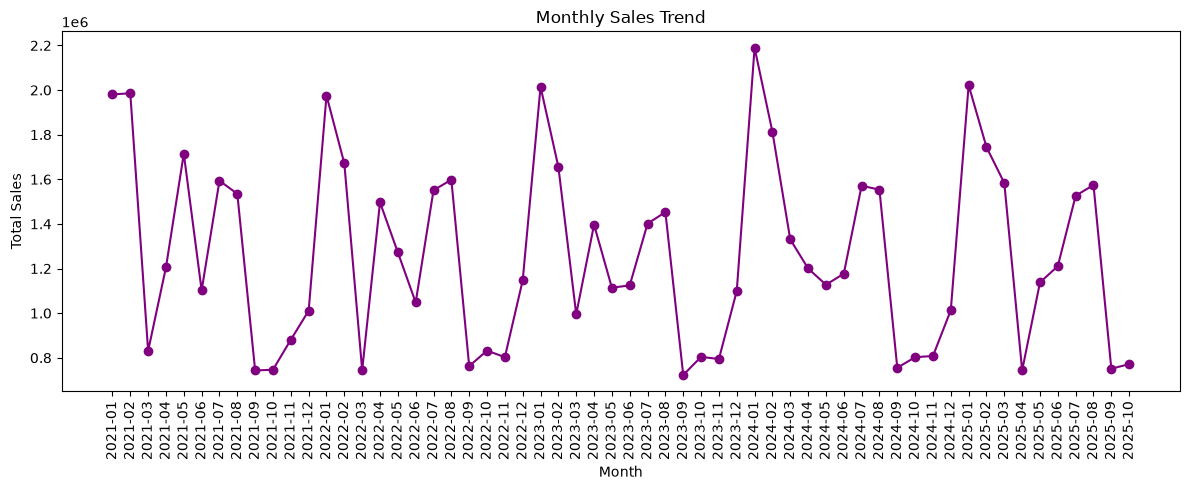

In [56]:
# for over the time the best visualization is line chart
plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index,monthly_sales.values,marker='o',color='purple')
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 2. Profit and exploratory analysis
`profit = total_value - quantity x cost_price`

Checks done: `total_value = quantity x sales_price`, and `sales_price` already equals `list_price x (1 - discount)`. The discount is therefore already inside `total_value` and must not be applied again. 1.6% of sales are loss-making (discounted below cost).

In [57]:
#profit=total value-quantity*cost price
df['profit']=df['total_value']-(df['quantity']*df['cost_price'])

In [58]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,gender,customer_city,loyalty_segment,preferred_channel,registration_date,store_name,city,store_type,opening_date,profit
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,Female,Dubai,Silver,Website,2024-12-19,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,Female,Dubai,Silver,Amazon.ae,2025-03-16,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,419.64
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,Female,Dubai,Gold,MobileApp,2024-11-20,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,2.69


In [59]:
print((df['total_value'] - df['quantity']*df['sales_price']).abs().max())

2.2737367544323206e-13


In [60]:
ratio = df['sales_price'] / df['list_price']
expected = 1 - df['discount_percentage']/100
print((ratio - expected).abs().max())

0.0014084507042253502


In [61]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,gender,customer_city,loyalty_segment,preferred_channel,registration_date,store_name,city,store_type,opening_date,profit
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,Female,Dubai,Silver,Website,2024-12-19,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,Female,Dubai,Silver,Amazon.ae,2025-03-16,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,419.64
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,Female,Dubai,Gold,MobileApp,2024-11-20,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,2.69


In [62]:
   print((df['profit'] == df['total_value'] - df['quantity'] * df['cost_price']).all())

True


**Findings:** total sales are about 73.2M. Electronics is 56% of sales. Volume halves every September and rises again in December, in every year of the data, so this is seasonality and not an error. From August to October the online channels fall 62-70%, while the Store channel falls only 30%.

In [63]:
category_perf=df.groupby('category').agg(total_sales=('total_value','sum'),
                          total_profit=('profit','sum')).sort_values('total_sales',ascending=False)
category_perf


,total_sales,total_profit
category,,
Electronics,40790950.89,11848265.14
Household,8190735.92,2360418.07
Personal Care,8181799.29,2115959.34
Grocery,5564702.41,1661022.56
Snacks,4321275.25,1299444.11
Dairy,4238161.64,1237884.73
Beverages,1922157.59,574416.61


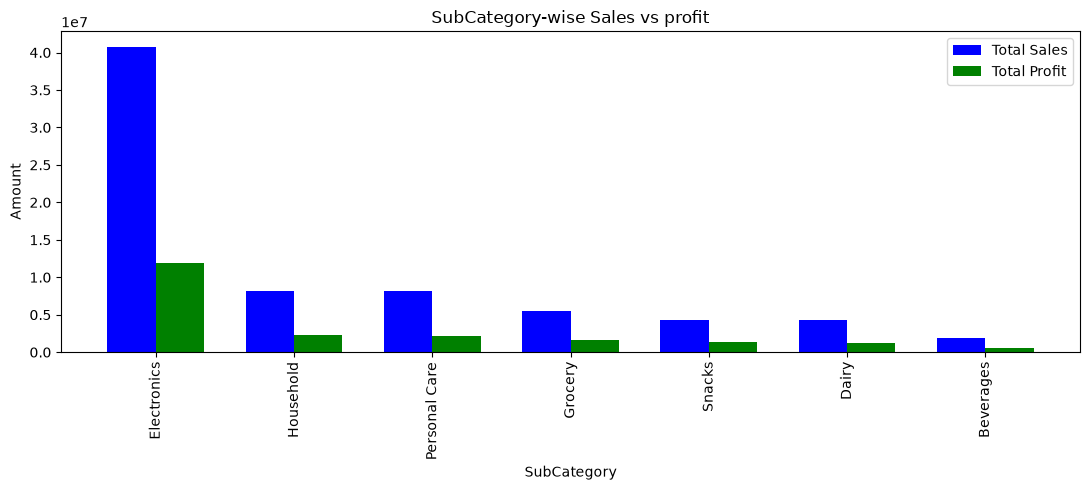

In [64]:
#category ka visualization ke liye hum bar chat use kare ge
x=np.arange(len(category_perf))
width=0.35
plt.figure(figsize=(11,5))
plt.bar(x-width/2,category_perf['total_sales'],width=width,label='Total Sales',color='blue')
plt.bar(x+width/2,category_perf['total_profit'],width=width,label='Total Profit',color='green')
plt.xticks(x,category_perf.index,rotation=90)
plt.ylabel("Amount")
plt.xlabel("SubCategory")
plt.title("SubCategory-wise Sales vs profit")
plt.legend()
plt.tight_layout()
plt.show()

In [65]:
# which product are the most profitable
product_perf=df.groupby('subcategory').agg(total_sales=('total_value','sum'),
                                          total_profit=('profit','sum'))
product_perf=product_perf.sort_values('total_profit',ascending=False)
top_ten_profitable=product_perf.head(10)
top_ten_profitable

,total_sales,total_profit
subcategory,,
Batteries,12530863.56,3961439.04
Cables,11490862.59,3393750.71
Chargers,9227916.96,2311019.26
Mobile Accessories,7541307.78,2182056.13
Cleaning Supplies,3138214.56,898445.37
Paper Products,2745043.37,743314.52
Toothpaste,2403497.14,655592.68
Skincare,2424275.35,551642.10
Canned Goods,1375868.80,449469.99


In [66]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,gender,customer_city,loyalty_segment,preferred_channel,registration_date,store_name,city,store_type,opening_date,profit
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,Female,Dubai,Silver,Website,2024-12-19,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,Female,Dubai,Silver,Amazon.ae,2025-03-16,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,419.64
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,Female,Dubai,Gold,MobileApp,2024-11-20,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,2.69


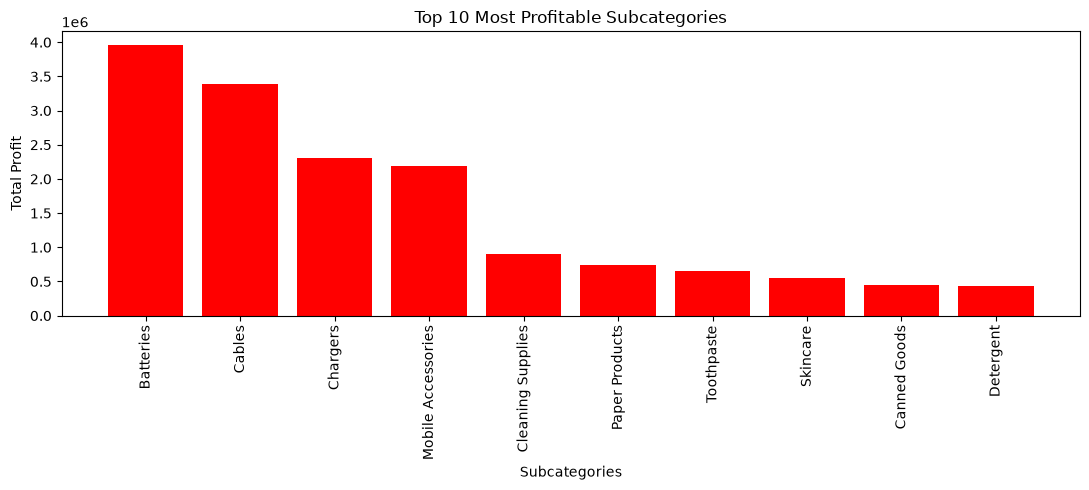

In [67]:
plt.figure(figsize=(11,5))
plt.bar(top_ten_profitable.index,top_ten_profitable['total_profit'],color='red')
plt.xlabel("Subcategories")
plt.ylabel("Total Profit")
plt.title("Top 10 Most Profitable Subcategories")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [68]:
# which store and cities are performing best
store_perf=df.groupby('store_name')['total_value'].sum().sort_values(ascending=False)
store_perf.head(10)


store_name
BlueMart Store 41    1500094.91
BlueMart Store 11    1495245.74
BlueMart Store 49    1494703.15
BlueMart Store 44    1493356.50
BlueMart Store 04    1492536.75
BlueMart Store 37    1489346.54
BlueMart Store 35    1486546.13
BlueMart Store 08    1486405.93
BlueMart Store 17    1484028.19
BlueMart Store 19    1481028.59
Name: total_value, dtype: float64

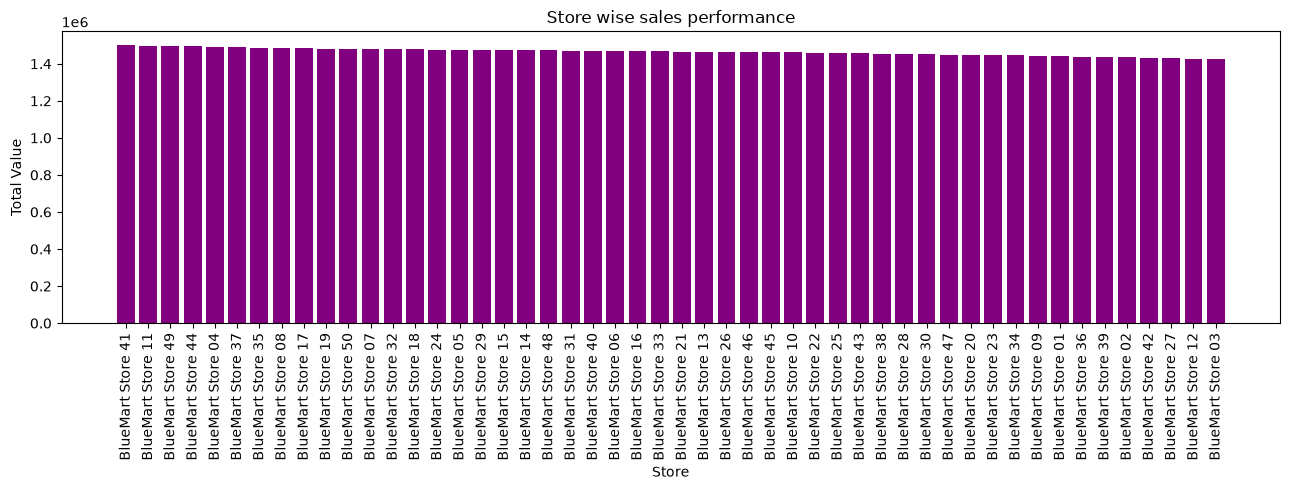

In [69]:
#Store bar chart
plt.figure(figsize=(13,5))
plt.bar(store_perf.index,store_perf.values,color='purple')
plt.xlabel("Store")
plt.ylabel("Total Value")
plt.title("Store wise sales performance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

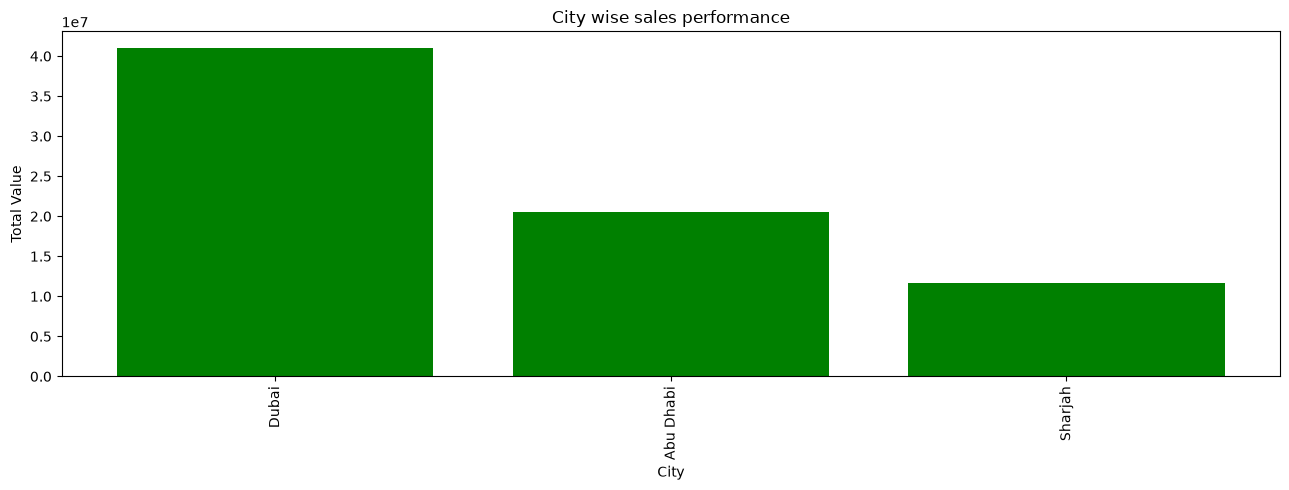

In [70]:
city_perf=df.groupby('city')['total_value'].sum().sort_values(ascending=False)
plt.figure(figsize=(13,5))
plt.bar(city_perf.index,city_perf.values,color='green')
plt.xlabel("City")
plt.ylabel("Total Value")
plt.title("City wise sales performance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [71]:
channel_perf=df.groupby('channel')['total_value'].sum().sort_values(ascending=False)
channel_perf

channel
Store        30227603.54
Website      20299836.60
MobileApp    13097435.70
Amazon.ae     6470717.92
Noon          3114189.23
Name: total_value, dtype: float64

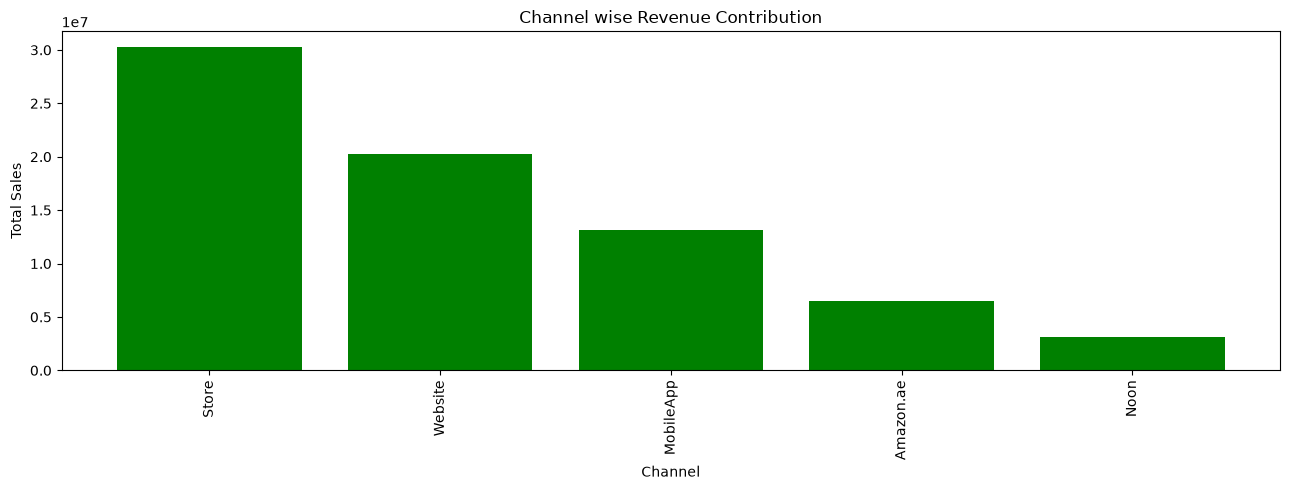

In [72]:
plt.figure(figsize=(13,5))
plt.bar(channel_perf.index,channel_perf.values,color='green')
plt.xlabel("Channel")
plt.ylabel("Total Sales")
plt.title("Channel wise Revenue Contribution")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [73]:
#loading the inventory dataset
idf=pd.read_csv('bm_inventory.csv')

In [74]:
idf.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,9,1101,300,92,46,2025-10-18,2025-10-31
1,9,1021,425,162,81,2025-10-21,2025-10-31
2,9,1200,252,85,42,2025-09-14,2025-10-31
3,9,1041,220,87,43,2025-10-13,2025-10-31
4,9,1092,170,80,40,2025-09-12,2025-10-31


In [75]:
idf.shape

(8735, 7)

In [76]:
idf.info()

<class 'pandas.DataFrame'>
RangeIndex: 8735 entries, 0 to 8734
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   store_id           8735 non-null   int64
 1   sku_id             8735 non-null   int64
 2   stock_on_hand      8735 non-null   int64
 3   reorder_point      8735 non-null   int64
 4   safety_stock       8735 non-null   int64
 5   last_restock_date  8735 non-null   str  
 6   snapshot_date      8735 non-null   str  
dtypes: int64(5), str(2)
memory usage: 648.4 KB


In [77]:
idf.rename(columns={'sku_id':'product_id'},inplace=True)

In [78]:
idf.columns

Index(['store_id', 'product_id', 'stock_on_hand', 'reorder_point',
       'safety_stock', 'last_restock_date', 'snapshot_date'],
      dtype='str')

In [79]:
idf.isna().sum()

store_id             0
product_id           0
stock_on_hand        0
reorder_point        0
safety_stock         0
last_restock_date    0
snapshot_date        0
dtype: int64

In [80]:
idf.duplicated().sum()

np.int64(0)

In [81]:
idf['last_restock_date']=pd.to_datetime(idf['last_restock_date'])
idf['snapshot_date']=pd.to_datetime(idf['snapshot_date'])


In [82]:
idf.info()

<class 'pandas.DataFrame'>
RangeIndex: 8735 entries, 0 to 8734
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   store_id           8735 non-null   int64         
 1   product_id         8735 non-null   int64         
 2   stock_on_hand      8735 non-null   int64         
 3   reorder_point      8735 non-null   int64         
 4   safety_stock       8735 non-null   int64         
 5   last_restock_date  8735 non-null   datetime64[us]
 6   snapshot_date      8735 non-null   datetime64[us]
dtypes: datetime64[us](2), int64(5)
memory usage: 477.8 KB


In [83]:
idf['product_id'].isin(sdf['product_id']).all()

np.True_

In [84]:
print((idf['stock_on_hand'] < 0).sum())
print((idf['last_restock_date'] > idf['snapshot_date']).sum())
print(idf['snapshot_date'].nunique())

0
0
1


In [85]:
print(idf.duplicated(['product_id']).sum())

8535


In [86]:
print("Original sales rows:", len(sdf))
print("Merged dataset rows:", len(df))

Original sales rows: 641798
Merged dataset rows: 641798


In [87]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,gender,customer_city,loyalty_segment,preferred_channel,registration_date,store_name,city,store_type,opening_date,profit
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,Female,Dubai,Silver,Website,2024-12-19,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,NaN,NaN,NaN,NaN,NaT,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,Female,Dubai,Silver,Amazon.ae,2025-03-16,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,419.64
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,Female,Dubai,Gold,MobileApp,2024-11-20,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,2.69


In [88]:
df = pd.merge(
    df,
    idf,
    on=['product_id', 'store_id'],
    how='left'
)

In [89]:
df.head()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,channel,discount_percentage,product_name,...,store_name,city,store_type,opening_date,profit,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,...,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46,95.0,35.0,17.0,2025-08-04,2025-10-31
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,...,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97,79.0,34.0,17.0,2025-09-15,2025-10-31
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,...,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67,87.0,29.0,14.0,2025-10-16,2025-10-31
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,...,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,419.64,84.0,38.0,19.0,2025-08-06,2025-10-31
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,...,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,2.69,222.0,107.0,53.0,2025-09-25,2025-10-31


In [90]:
df.shape

(641798, 31)

In [91]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 641798 entries, 0 to 641797
Data columns (total 31 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 641798 non-null  datetime64[us]
 1   store_id             641798 non-null  int64         
 2   product_id           641798 non-null  int64         
 3   customer_id          482021 non-null  float64       
 4   quantity             641798 non-null  int64         
 5   sales_price          641798 non-null  float64       
 6   total_value          641798 non-null  float64       
 7   channel              641798 non-null  str           
 8   discount_percentage  641798 non-null  float64       
 9   product_name         641798 non-null  str           
 10  category             641798 non-null  str           
 11  subcategory          641798 non-null  str           
 12  list_price           641798 non-null  float64       
 13  cost_price           6417

In [92]:
df.describe()

,date,store_id,product_id,customer_id,quantity,sales_price,total_value,discount_percentage,list_price,cost_price,age,registration_date,opening_date,profit,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
count,641798,641798.000000,641798.000000,482021.000000,641798.000000,641798.000000,641798.000000,641798.000000,641798.000000,641798.000000,482021.000000,482021,641798,641798.000000,560884.000000,560884.000000,560884.000000,560884,560884
mean,2023-05-20 21:38:14.056385,25.491155,1100.547867,2504.984928,2.613163,44.108567,114.069821,5.411391,46.633468,31.031957,31.081293,2023-05-24 02:12:14.651809,2017-08-02 08:35:44.990380800,32.872353,170.802909,67.769826,33.636574,2025-09-16 01:51:25.138460,2025-10-30 23:59:59.999999
min,2021-01-01 00:00:00,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000,2.610000,1.680000,18.000000,2021-01-01 00:00:00,2017-01-01 00:00:00,-196.800000,35.000000,10.000000,5.000000,2025-08-03 00:00:00,2025-10-31 00:00:00
25%,2022-02-25 00:00:00,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000,15.160000,10.070000,20.000000,2022-03-03 00:00:00,2017-05-31 00:00:00,7.120000,112.000000,43.000000,21.000000,2025-08-25 00:00:00,2025-10-31 00:00:00
50%,2023-05-19 00:00:00,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000,25.910000,17.120000,30.000000,2023-06-06 00:00:00,2017-08-02 15:48:17.560975616,15.990000,156.000000,62.000000,31.000000,2025-09-16 00:00:00,2025-10-31 00:00:00
75%,2024-07-31 00:00:00,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000,50.490000,34.180000,35.000000,2024-08-04 00:00:00,2017-10-12 21:04:23.414634240,36.470000,217.000000,87.000000,43.000000,2025-10-08 00:00:00,2025-10-31 00:00:00
max,2025-10-31 00:00:00,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000,245.380000,187.670000,60.000000,2025-10-30 00:00:00,2018-01-01 00:00:00,634.800000,449.000000,217.000000,108.000000,2025-10-30 00:00:00,2025-10-31 00:00:00
std,NaN,14.437393,57.684126,1442.341147,1.481571,48.983286,157.202054,8.664765,51.386056,34.299161,10.740235,NaN,NaN,50.170309,77.872430,33.015876,16.512533,NaN,NaN


In [93]:
missing_inventory = df[df['stock_on_hand'].isna()]

print("Missing inventory rows:", len(missing_inventory))

missing_inventory[['product_id', 'store_id']].head(10)

Missing inventory rows: 80914


,product_id,store_id
10,1036,13
12,1048,9
26,1149,23
28,1027,11
35,1164,47
36,1081,21
37,1085,41
45,1104,20
52,1177,7
57,1051,12


In [94]:
# Check whether each product-store combination exists in inventory

inventory_keys = idf[['product_id', 'store_id']].drop_duplicates()

sales_keys = df[['product_id', 'store_id']].drop_duplicates()

missing_keys = sales_keys.merge(
    inventory_keys,
    on=['product_id', 'store_id'],
    how='left',
    indicator=True
)

print(missing_keys['_merge'].value_counts())

_merge
both          8735
left_only     1265
right_only       0
Name: count, dtype: int64


In [95]:
missing_products = set(sdf['product_id']) - set(idf['product_id'])
missing_stores = set(sdf['store_id']) - set(idf['store_id'])

print("Products absent from inventory:", len(missing_products))
print("Stores absent from inventory:", len(missing_stores))

Products absent from inventory: 0
Stores absent from inventory: 0


## 3. Demand forecasting
Daily demand per product is only about 2-3 units, so daily forecasts were mostly noise (WAPE about 70-135%). Forecasting was moved to **weekly** demand for the top 5 products. Models were tested with a time-based split and compared against honest baselines: repeat last week, 28-day average, and same weeks last year.

In [96]:
# Convert date to datetime format
sdf['date'] = pd.to_datetime(sdf['date'])

# Aggregate sales by date and product
daily_sales = (
    sdf.groupby(['date', 'product_id'], as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('total_value', 'sum')
    )
)

# Display the results
print("Daily Sales Shape:", daily_sales.shape)

display(daily_sales.head())

print("\nDate Range:")
print(daily_sales['date'].min(), "to", daily_sales['date'].max())

print("\nMissing Values:")
print(daily_sales.isnull().sum())

Daily Sales Shape: (286348, 4)


,date,product_id,total_quantity,total_sales
0,2021-01-01,1001,7,1102.56
1,2021-01-01,1002,6,70.02
2,2021-01-01,1003,6,61.20
3,2021-01-01,1006,3,32.19
4,2021-01-01,1007,12,756.67



Date Range:
2021-01-01 00:00:00 to 2025-10-31 00:00:00

Missing Values:
date              0
product_id        0
total_quantity    0
total_sales       0
dtype: int64


In [97]:
full_date=pd.date_range(daily_sales['date'].min(),daily_sales['date'].max(),freq='D')
idx=pd.MultiIndex.from_product([full_date,daily_sales['product_id'].unique()],
                              names=['date','product_id'])
daily_sales=(daily_sales.set_index(['date','product_id'])
            .reindex(idx,fill_value=0)
            .reset_index())
print(daily_sales.shape)

(353000, 4)


In [98]:
top_product=(daily_sales.groupby('product_id')['total_quantity']
            .sum().sort_values(ascending=False).head(5).index.tolist())
print(top_product)
cutoff=daily_sales['date'].max()-pd.Timedelta(days=30)
train=daily_sales[daily_sales['date']<=cutoff]
test=daily_sales[daily_sales['date']>cutoff]
print("Train",train['date'].min(),"to",train['date'].max())
print("Test",test['date'].min(),'to',test['date'].max())

[1194, 1156, 1059, 1111, 1167]
Train 2021-01-01 00:00:00 to 2025-10-01 00:00:00
Test 2025-10-02 00:00:00 to 2025-10-31 00:00:00


In [99]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def wape(y, yhat):
    return np.abs(y - yhat).sum() / y.sum() * 100

results = []
for pid in top_product:
    s = (daily_sales[daily_sales['product_id'] == pid]
         .set_index('date')['total_quantity'])
    s_train, s_test = s[s.index <= cutoff], s[s.index > cutoff]

    # Baseline A: repeat last training week
    pred_week = np.tile(s_train.iloc[-7:].values, 5)[:len(s_test)]
    # Baseline B: average of last 28 training days
    pred_avg = np.full(len(s_test), s_train.iloc[-28:].mean())

    for name, pred in [('last_week_repeat', pred_week), ('avg_last_28d', pred_avg)]:
        results.append({
            'product_id': pid, 'model': name,
            'MAE': mean_absolute_error(s_test, pred),
            'RMSE': np.sqrt(mean_squared_error(s_test, pred)),
            'WAPE_%': wape(s_test.values, pred)
        })
baseline_results = pd.DataFrame(results)
baseline_results

,product_id,model,MAE,RMSE,WAPE_%
0,1194,last_week_repeat,3.100000,3.937004,134.782609
1,1194,avg_last_28d,2.576190,2.900563,112.008282
2,1156,last_week_repeat,2.866667,3.296463,101.176471
3,1156,avg_last_28d,1.995238,2.510522,70.420168
4,1059,last_week_repeat,3.433333,4.207137,132.051282
5,1059,avg_last_28d,2.176190,2.784905,83.699634
6,1111,last_week_repeat,2.633333,3.209361,149.056604
7,1111,avg_last_28d,2.280952,2.544502,129.110512
8,1167,last_week_repeat,3.900000,5.003332,118.181818
9,1167,avg_last_28d,2.466667,3.232646,74.747475


In [100]:
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)   # hides the log spam

from prophet import Prophet
prophet_results = []
forecasts = {}
for pid in top_product:
    d = (daily_sales[daily_sales['product_id'] == pid]
         [['date', 'total_quantity']].rename(columns={'date': 'ds', 'total_quantity': 'y'}))
    d_train, d_test = d[d['ds'] <= cutoff], d[d['ds'] > cutoff]
    m = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
    m.add_country_holidays(country_name='AE')
    m.fit(d_train)
    fc = m.predict(d_test[['ds']])
    yhat = fc['yhat'].clip(lower=0).values
    forecasts[pid] = (m, fc)
    prophet_results.append({
        'product_id': pid, 'model': 'prophet',
        'MAE': mean_absolute_error(d_test['y'], yhat),
        'RMSE': np.sqrt(mean_squared_error(d_test['y'], yhat)),
        'WAPE_%': wape(d_test['y'].values, yhat)
    })
prophet_results = pd.DataFrame(prophet_results)
comparison = pd.concat([baseline_results, prophet_results]).sort_values(['product_id', 'WAPE_%'])
comparison

10:13:38 - cmdstanpy - INFO - Chain [1] start processing
10:13:38 - cmdstanpy - INFO - Chain [1] done processing
10:13:38 - cmdstanpy - INFO - Chain [1] start processing
10:13:38 - cmdstanpy - INFO - Chain [1] done processing
10:13:38 - cmdstanpy - INFO - Chain [1] start processing
10:13:38 - cmdstanpy - INFO - Chain [1] done processing
10:13:39 - cmdstanpy - INFO - Chain [1] start processing
10:13:39 - cmdstanpy - INFO - Chain [1] done processing
10:13:39 - cmdstanpy - INFO - Chain [1] start processing
10:13:39 - cmdstanpy - INFO - Chain [1] done processing


,product_id,model,MAE,RMSE,WAPE_%
5,1059,avg_last_28d,2.176190,2.784905,83.699634
2,1059,prophet,2.396918,3.016298,92.189151
4,1059,last_week_repeat,3.433333,4.207137,132.051282
7,1111,avg_last_28d,2.280952,2.544502,129.110512
3,1111,prophet,2.397419,2.734452,135.702947
6,1111,last_week_repeat,2.633333,3.209361,149.056604
3,1156,avg_last_28d,1.995238,2.510522,70.420168
1,1156,prophet,2.272852,2.777199,80.218309
2,1156,last_week_repeat,2.866667,3.296463,101.176471
4,1167,prophet,2.384029,3.107499,72.243301


In [101]:
# weekly demand (after zero-fill), full weeks only
weekly = (daily_sales.set_index('date')
          .groupby('product_id')['total_quantity']
          .resample('W').sum().reset_index())
weekly = weekly[(weekly['date'] >= '2021-01-10') & (weekly['date'] <= '2025-10-26')]

test_weeks = 4
res = []
for pid in top_product:
    w = weekly[weekly['product_id'] == pid].set_index('date')['total_quantity']
    w_train, w_test = w.iloc[:-test_weeks], w.iloc[-test_weeks:]

    preds = {
        'last_week_repeat': np.full(test_weeks, w_train.iloc[-1]),
        'avg_last_8w': np.full(test_weeks, w_train.iloc[-8:].mean()),
    }
    d = w_train.reset_index().rename(columns={'date': 'ds', 'total_quantity': 'y'})
    m = Prophet(weekly_seasonality=False, yearly_seasonality=True, daily_seasonality=False)
    m.fit(d)
    fc = m.predict(pd.DataFrame({'ds': w_test.index}))
    preds['prophet'] = fc['yhat'].clip(lower=0).values

    for name, p in preds.items():
        res.append({'product_id': pid, 'model': name,
                    'MAE': mean_absolute_error(w_test, p),
                    'WAPE_%': wape(w_test.values, p)})

weekly_comparison = pd.DataFrame(res).sort_values(['product_id', 'WAPE_%'])
weekly_comparison

10:13:40 - cmdstanpy - INFO - Chain [1] start processing
10:13:40 - cmdstanpy - INFO - Chain [1] done processing
10:13:40 - cmdstanpy - INFO - Chain [1] start processing
10:13:40 - cmdstanpy - INFO - Chain [1] done processing
10:13:40 - cmdstanpy - INFO - Chain [1] start processing
10:13:40 - cmdstanpy - INFO - Chain [1] done processing
10:13:40 - cmdstanpy - INFO - Chain [1] start processing
10:13:40 - cmdstanpy - INFO - Chain [1] done processing
10:13:40 - cmdstanpy - INFO - Chain [1] start processing
10:13:40 - cmdstanpy - INFO - Chain [1] done processing


,product_id,model,MAE,WAPE_%
6,1059,last_week_repeat,4.750000,28.358209
8,1059,prophet,4.942291,29.506215
7,1059,avg_last_8w,13.375000,79.850746
11,1111,prophet,9.942064,82.850537
9,1111,last_week_repeat,12.000000,100.000000
10,1111,avg_last_8w,20.250000,168.750000
3,1156,last_week_repeat,6.250000,36.231884
5,1156,prophet,6.263687,36.311230
4,1156,avg_last_8w,11.000000,63.768116
12,1167,last_week_repeat,4.250000,20.987654


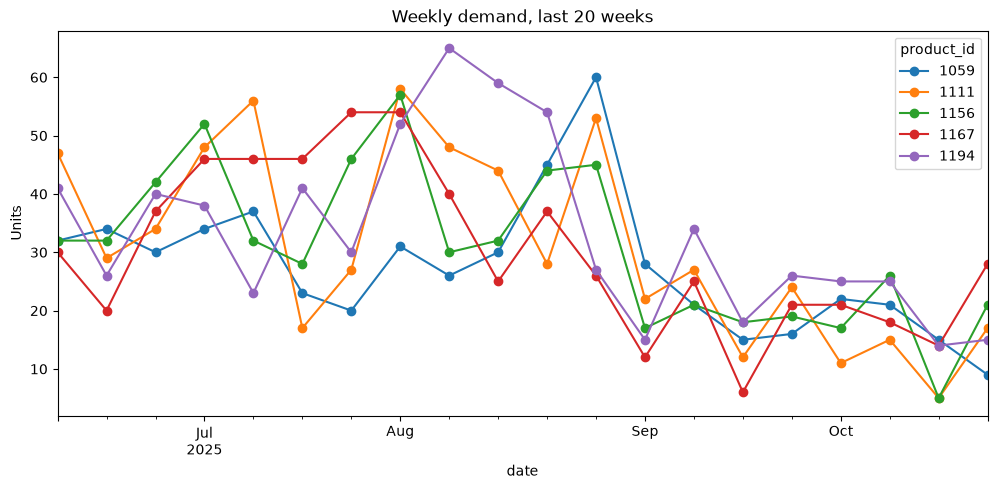

date
2025-08-10    7860
2025-08-17    7750
2025-08-24    7119
2025-08-31    8204
2025-09-07    3949
2025-09-14    3882
2025-09-21    3464
2025-09-28    3690
2025-10-05    3794
2025-10-12    4086
2025-10-19    3020
2025-10-26    3858
Name: total_quantity, dtype: int64


In [102]:
w = weekly[weekly['product_id'].isin(top_product)]
pivot = w.pivot(index='date', columns='product_id', values='total_quantity')
pivot.tail(20).plot(figsize=(12,5), marker='o', title='Weekly demand, last 20 weeks')
plt.ylabel('Units'); plt.show()

print(weekly.groupby('date')['total_quantity'].sum().tail(12))

In [103]:
a = df[(df['date'] >= '2025-08-01') & (df['date'] <= '2025-08-31')]
b = df[(df['date'] >= '2025-10-01') & (df['date'] <= '2025-10-31')]

for col in ['channel', 'category', 'city']:
    cmp = pd.DataFrame({'Aug': a.groupby(col)['quantity'].sum(),
                        'Oct': b.groupby(col)['quantity'].sum()})
    cmp['change_%'] = ((cmp['Oct'] / cmp['Aug'] - 1) * 100).round(1)
    print(cmp.sort_values('change_%'), '\n')

# stores: how many stopped selling?
st = pd.DataFrame({'Aug': a.groupby('store_id')['quantity'].sum(),
                   'Oct': b.groupby('store_id')['quantity'].sum()}).fillna(0)
st['change_%'] = ((st['Oct'] / st['Aug'] - 1) * 100).round(1)
print(st.sort_values('change_%').head(15))
print("stores with zero sales in Oct:", (st['Oct'] == 0).sum())

             Aug   Oct  change_%
channel                         
Noon        1672   497     -70.3
Amazon.ae   3639  1159     -68.2
MobileApp   7243  2326     -67.9
Website    10661  4054     -62.0
Store      12324  8592     -30.3 

                Aug   Oct  change_%
category                           
Electronics    7946  3488     -56.1
Personal Care  3862  1773     -54.1
Snacks         7019  3255     -53.6
Dairy          4443  2111     -52.5
Household      5394  2567     -52.4
Grocery        4117  2043     -50.4
Beverages      2758  1391     -49.6 

             Aug   Oct  change_%
city                            
Sharjah     5542  2501     -54.9
Abu Dhabi  10315  4713     -54.3
Dubai      19682  9414     -52.2 

          Aug  Oct  change_%
store_id                    
28        808  294     -63.6
36        785  294     -62.5
18        838  324     -61.3
38        704  273     -61.2
47        685  271     -60.4
40        805  324     -59.8
32        748  307     -59.0
8         725

In [104]:
# 1. Monthly units, number of transactions, and average discount
m = df.groupby(df['date'].dt.to_period('M')).agg(
    units=('quantity', 'sum'),
    rows=('quantity', 'size'),
    avg_discount=('discount_percentage', 'mean'))
print(m.tail(18))

# 2. Was there the same Aug-to-Oct drop in earlier years?
for y in range(2021, 2026):
    a = df[(df['date'] >= f'{y}-08-01') & (df['date'] <= f'{y}-08-31')]['quantity'].sum()
    o = df[(df['date'] >= f'{y}-10-01') & (df['date'] <= f'{y}-10-31')]['quantity'].sum()
    print(y, a, o, round((o / a - 1) * 100, 1), '%')

# 3. Exact date of the drop
daily_total = df.groupby('date')['quantity'].sum()
print(daily_total['2025-08-28':'2025-09-10'])

         units   rows  avg_discount
date                               
2024-05  24252  12169      0.000000
2024-06  26018  12205      2.025399
2024-07  35936  11523      6.031415
2024-08  35291  11298      5.992211
2024-09  16305   8075      0.000000
2024-10  17546   8762      0.000000
2024-11  17675   8443      1.649887
2024-12  22314  10377      1.418040
2025-01  48154  15338      9.041270
2025-02  41072  13122      8.944902
2025-03  42138  13435     18.091552
2025-04  16472   7868      1.513726
2025-05  24936  12480      0.000000
2025-06  27039  12467      2.350205
2025-07  34289  10897      5.988804
2025-08  35539  11307      5.932608
2025-09  16049   8052      0.000000
2025-10  16628   8302      0.000000
2021 34898 16312 -53.3 %
2022 36154 17892 -50.5 %
2023 35339 17163 -51.4 %
2024 35291 17546 -50.3 %
2025 35539 16628 -53.2 %
date
2025-08-28    1154
2025-08-29    1127
2025-08-30    1340
2025-08-31    1514
2025-09-01     473
2025-09-02     562
2025-09-03     398
2025-09-04     69

**Rolling backtest:** 13 four-week windows covering a full year. Prophet had the lowest error on all 5 products (average WAPE 33.7% vs 37.7% for the best baseline), a modest but consistent gain. The November forecast was cross-checked against each product's own seasonal history and blended with a seasonal-ratio estimate. Product 1111 is low confidence: the two methods disagree by 28 units.

In [105]:
def backtest(w, n_windows=13, h=4):
    rows = []
    for k in range(n_windows, 0, -1):
        end = len(w) - (k - 1) * h
        tr, te = w.iloc[:end - h], w.iloc[end - h:end]

        p_last = np.full(h, tr.iloc[-1])                   # repeat last week
        p_ly = w.shift(52).iloc[end - h:end].values        # same weeks last year
        d = tr.reset_index().rename(columns={'date': 'ds', 'total_quantity': 'y'})
        m = Prophet(weekly_seasonality=False, yearly_seasonality=True,
                    daily_seasonality=False).fit(d)
        p_prophet = m.predict(pd.DataFrame({'ds': te.index}))['yhat'].clip(lower=0).values

        for name, p in [('last_week_repeat', p_last),
                        ('same_weeks_last_year', p_ly),
                        ('prophet', p_prophet)]:
            rows.append({'model': name, 'window_end': te.index[-1],
                         'abs_err': np.abs(te.values - p).sum(),
                         'actual': te.values.sum()})
    return pd.DataFrame(rows)

all_bt = []
for pid in top_product:
    w = weekly[weekly['product_id'] == pid].set_index('date')['total_quantity']
    bt = backtest(w)
    bt['product_id'] = pid
    all_bt.append(bt)
all_bt = pd.concat(all_bt)

summary = (all_bt.groupby(['product_id', 'model'])
           .apply(lambda g: g['abs_err'].sum() / g['actual'].sum() * 100)
           .rename('WAPE_%').reset_index().sort_values(['product_id', 'WAPE_%']))
summary

10:13:41 - cmdstanpy - INFO - Chain [1] start processing
10:13:41 - cmdstanpy - INFO - Chain [1] done processing
10:13:41 - cmdstanpy - INFO - Chain [1] start processing
10:13:41 - cmdstanpy - INFO - Chain [1] done processing
10:13:41 - cmdstanpy - INFO - Chain [1] start processing
10:13:41 - cmdstanpy - INFO - Chain [1] done processing
10:13:41 - cmdstanpy - INFO - Chain [1] start processing
10:13:41 - cmdstanpy - INFO - Chain [1] done processing
10:13:41 - cmdstanpy - INFO - Chain [1] start processing
10:13:42 - cmdstanpy - INFO - Chain [1] done processing
10:13:42 - cmdstanpy - INFO - Chain [1] start processing
10:13:42 - cmdstanpy - INFO - Chain [1] done processing
10:13:42 - cmdstanpy - INFO - Chain [1] start processing
10:13:42 - cmdstanpy - INFO - Chain [1] done processing
10:13:42 - cmdstanpy - INFO - Chain [1] start processing
10:13:42 - cmdstanpy - INFO - Chain [1] done processing
10:13:42 - cmdstanpy - INFO - Chain [1] start processing
10:13:42 - cmdstanpy - INFO - Chain [1]

,product_id,model,WAPE_%
1,1059,prophet,34.492733
2,1059,same_weeks_last_year,40.057143
0,1059,last_week_repeat,49.257143
4,1111,prophet,41.756310
3,1111,last_week_repeat,47.984100
5,1111,same_weeks_last_year,48.722317
7,1156,prophet,29.630912
8,1156,same_weeks_last_year,32.402529
6,1156,last_week_repeat,51.422550
10,1167,prophet,31.932930


In [106]:
future_rows = []
for pid in top_product:
    w = weekly[weekly['product_id'] == pid].set_index('date')['total_quantity']
    d = w.reset_index().rename(columns={'date': 'ds', 'total_quantity': 'y'})
    m = Prophet(weekly_seasonality=False, yearly_seasonality=True,
                daily_seasonality=False).fit(d)
    fut = m.make_future_dataframe(periods=4, freq='W')
    fc = m.predict(fut).tail(4)[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
    fc[['yhat', 'yhat_lower', 'yhat_upper']] = fc[['yhat', 'yhat_lower', 'yhat_upper']].clip(lower=0)
    fc['product_id'] = pid
    future_rows.append(fc)

future_fc = pd.concat(future_rows)
future_fc.round(1)

10:13:51 - cmdstanpy - INFO - Chain [1] start processing
10:13:51 - cmdstanpy - INFO - Chain [1] done processing
10:13:51 - cmdstanpy - INFO - Chain [1] start processing
10:13:51 - cmdstanpy - INFO - Chain [1] done processing
10:13:51 - cmdstanpy - INFO - Chain [1] start processing
10:13:51 - cmdstanpy - INFO - Chain [1] done processing
10:13:51 - cmdstanpy - INFO - Chain [1] start processing
10:13:51 - cmdstanpy - INFO - Chain [1] done processing
10:13:51 - cmdstanpy - INFO - Chain [1] start processing
10:13:51 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\Abhishek\AppData\Local\Temp\ipykernel_14292\1840431974.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  future_fc.round(1)


,ds,yhat,yhat_lower,yhat_upper,product_id
251,2025-11-02,21.2,4.5,38.3,1194
252,2025-11-09,22.1,5.4,38.4,1194
253,2025-11-16,24.4,7.3,41.2,1194
254,2025-11-23,27.9,10.3,45.4,1194
251,2025-11-02,19.4,2.9,35.5,1156
252,2025-11-09,20.7,4.4,38.0,1156
253,2025-11-16,23.3,6.3,40.2,1156
254,2025-11-23,27.7,10.6,45.4,1156
251,2025-11-02,15.1,0.0,32.3,1059
252,2025-11-09,13.7,0.0,30.5,1059


In [107]:
m = df.groupby([df['date'].dt.year.rename('year'),
                df['date'].dt.month.rename('month')])['quantity'].sum().unstack('year')
print(m.loc[[9, 10, 11, 12]])

year      2021     2022     2023     2024     2025
month                                             
9      15659.0  16284.0  15498.0  16305.0  16049.0
10     16312.0  17892.0  17163.0  17546.0  16628.0
11     19234.0  18466.0  18224.0  17675.0      NaN
12     21769.0  25052.0  24082.0  22314.0      NaN


## 4. Inventory
The data shows **overstock, not stockout risk**: 0 of 8,735 store-product rows are below their reorder point, and every row holds 2.0-3.6 times its reorder point. Stock is worth 38.9M at cost; 88% of it exceeds 26 weeks of demand (76% even at 52 weeks). Electronics holds 14.6M of the excess.

Limits: one inventory snapshot (31 Oct 2025), and demand is taken from the last 52 weeks.

In [108]:
below = idf['stock_on_hand'] < idf['reorder_point']
print("store-product rows below reorder point:", below.sum(), "of", len(idf))
print(idf[below].groupby('product_id').size().sort_values(ascending=False).head(10))

store-product rows below reorder point: 0 of 8735
Series([], dtype: int64)


In [109]:
inv = idf.groupby('product_id').agg(
    stock=('stock_on_hand', 'sum'),
    reorder_point=('reorder_point', 'sum'),
    stores_stocking=('store_id', 'nunique')).reset_index()

f = (future_fc.groupby('product_id')
     .agg(fc_4w=('yhat', 'sum'), fc_4w_high=('yhat_upper', 'sum')).reset_index())

plan = f.merge(inv, on='product_id', how='left')
plan['weeks_of_cover'] = plan['stock'] / (plan['fc_4w'] / 4)
plan['status'] = np.where(plan['stock'] < plan['fc_4w'], 'STOCKOUT RISK',
                  np.where(plan['stock'] < plan['fc_4w_high'], 'WATCH', 'OK'))
plan.round(1)

,product_id,fc_4w,fc_4w_high,stock,reorder_point,stores_stocking,weeks_of_cover,status
0,1059,72.7,141.4,5354,2081,46,294.7,OK
1,1111,76.1,144.3,8459,3326,42,444.7,OK
2,1156,91.2,159.1,6814,2678,44,298.9,OK
3,1167,78.2,143.9,9257,3739,44,473.4,OK
4,1194,95.7,163.2,7913,3170,45,330.8,OK


In [110]:
# 1. Rows below reorder point
below = idf['stock_on_hand'] < idf['reorder_point']
print("below reorder point:", below.sum(), "of", len(idf), f"({below.mean()*100:.1f}%)")

# 2. Stock relative to reorder point
idf['ratio'] = idf['stock_on_hand'] / idf['reorder_point']
print(idf['ratio'].describe())

# 3. Days since last restock
idf['days_since_restock'] = (idf['snapshot_date'] - idf['last_restock_date']).dt.days
print(idf['days_since_restock'].describe())

# 4. Cover at store-product level, using the last 8 weeks of real sales
recent = sdf[sdf['date'] > sdf['date'].max() - pd.Timedelta(weeks=8)]
wk = (recent.groupby(['store_id', 'product_id'])['quantity'].sum() / 8) \
        .rename('avg_weekly_units').reset_index()
chk = idf.merge(wk, on=['store_id', 'product_id'], how='left').fillna({'avg_weekly_units': 0})
chk['weeks_of_cover'] = chk['stock_on_hand'] / chk['avg_weekly_units'].replace(0, np.nan)
print(chk['weeks_of_cover'].describe())
print((chk['weeks_of_cover'] < 4).sum(), "store-product rows with under 4 weeks of cover")
print((chk['avg_weekly_units'] == 0).sum(), "rows with zero sales in the last 8 weeks (dead stock)")

below reorder point: 0 of 8735 (0.0%)
count    8735.000000
mean        2.582831
std         0.387765
min         2.004695
25%         2.242424
50%         2.530973
75%         2.888889
max         3.600000
Name: ratio, dtype: float64
count    8735.000000
mean       44.881397
std        25.680608
min         1.000000
25%        23.000000
50%        45.000000
75%        67.000000
max        89.000000
Name: days_since_restock, dtype: float64
count    6783.000000
mean      561.794919
std       518.091071
min        22.769231
25%       213.333333
50%       381.333333
75%       705.333333
max      3568.000000
Name: weeks_of_cover, dtype: float64
0 store-product rows with under 4 weeks of cover
1952 rows with zero sales in the last 8 weeks (dead stock)


In [111]:
window = 52
recent = sdf[sdf['date'] > sdf['date'].max() - pd.Timedelta(weeks=window)]
wk = (recent.groupby(['store_id', 'product_id'])['quantity'].sum() / window) \
        .rename('avg_weekly_units').reset_index()

chk = idf.merge(wk, on=['store_id', 'product_id'], how='left') \
         .fillna({'avg_weekly_units': 0}) \
         .merge(pdf[['product_id', 'category', 'cost_price']], on='product_id', how='left')

chk['stock_value'] = chk['stock_on_hand'] * chk['cost_price']
keep_weeks = 26   # assumption: more than half a year of demand counts as excess
chk['excess_units'] = (chk['stock_on_hand'] - chk['avg_weekly_units'] * keep_weeks).clip(lower=0)
chk['excess_value'] = chk['excess_units'] * chk['cost_price']

print("Total stock value:", round(chk['stock_value'].sum()))
print("Excess beyond 26 weeks:", round(chk['excess_value'].sum()),
      f"({chk['excess_value'].sum()/chk['stock_value'].sum()*100:.0f}% of stock value)")
print(chk.groupby('category')['excess_value'].sum().sort_values(ascending=False).round())
print("No sales in 52 weeks:", (chk['avg_weekly_units'] == 0).sum(), "rows")

Total stock value: 38914342
Excess beyond 26 weeks: 34280200 (88% of stock value)
category
Electronics      14610721.0
Personal Care     4558238.0
Grocery           4502403.0
Household         3937623.0
Snacks            2791201.0
Dairy             2503227.0
Beverages         1376788.0
Name: excess_value, dtype: float64
No sales in 52 weeks: 0 rows


In [112]:
for kw in [4, 13, 26, 52]:
    ex = (chk['stock_on_hand'] - chk['avg_weekly_units'] * kw).clip(lower=0) * chk['cost_price']
    print(f"keep {kw:>2} weeks of demand -> excess {ex.sum()/chk['stock_value'].sum()*100:.0f}% of stock value")

keep  4 weeks of demand -> excess 98% of stock value
keep 13 weeks of demand -> excess 94% of stock value
keep 26 weeks of demand -> excess 88% of stock value
keep 52 weeks of demand -> excess 76% of stock value


## 5. Customer segmentation (RFM + KMeans)
Customers are very similar (64-129 purchases each), so the silhouette score is only 0.29. The three segments are value tiers, not natural groups: High-value regulars, Recently active, and Low-spend cooling.

Loyalty tiers do not match behaviour: Platinum customers spend the same as Silver (10,950 vs 10,949).

In [113]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

reg = sdf[sdf['customer_id'].notna()].copy()
snapshot = reg['date'].max() + pd.Timedelta(days=1)

rfm = reg.groupby('customer_id').agg(
    recency=('date', lambda x: (snapshot - x.max()).days),
    frequency=('date', 'size'),          # purchase lines (no transaction ID in the data)
    monetary=('total_value', 'sum')).reset_index()
print(rfm.describe())

# log-scale to tame skew, then standardize
X = StandardScaler().fit_transform(np.log1p(rfm[['recency', 'frequency', 'monetary']]))

for k in range(3, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    print(k, round(silhouette_score(X, km.labels_), 3))

       customer_id      recency   frequency      monetary
count  5000.000000  5000.000000  5000.00000   5000.000000
mean   2500.500000    24.397200    96.40420  10975.370854
std    1443.520003    23.454284     9.81646   1863.676485
min       1.000000     1.000000    64.00000   5902.600000
25%    1250.750000     7.000000    90.00000   9679.505000
50%    2500.500000    18.000000    96.00000  10888.535000
75%    3750.250000    34.000000   103.00000  12192.035000
max    5000.000000   171.000000   129.00000  17773.230000
3 0.29
4 0.261
5 0.252
6 0.24


In [114]:
oct_total = (weekly[(weekly['date'] > '2025-09-28') & (weekly['product_id'].isin(top_product))]
             .groupby('product_id')['total_quantity'].sum())
fc_total = future_fc.groupby('product_id')['yhat'].sum()

check = pd.DataFrame({'last_4_weeks_actual': oct_total,
                      'next_4_weeks_forecast': fc_total.round(1)})
check['ratio'] = (check['next_4_weeks_forecast'] / check['last_4_weeks_actual']).round(2)
print(check)

            last_4_weeks_actual  next_4_weeks_forecast  ratio
product_id                                                   
1059                         67                   72.7   1.09
1111                         48                   76.1   1.59
1156                         69                   91.2   1.32
1167                         81                   78.2   0.97
1194                         79                   95.7   1.21


In [115]:
for pid in top_product:
    w = weekly[weekly['product_id'] == pid].set_index('date')['total_quantity']
    last4 = w.index[-4:]
    next4 = pd.date_range(last4[-1] + pd.Timedelta(weeks=1), periods=4, freq='W')
    ratios = []
    for yrs in [1, 2, 3, 4]:
        shift = pd.Timedelta(weeks=52 * yrs)
        prev = w.reindex(last4 - shift).sum()
        nxt = w.reindex(next4 - shift).sum()
        ratios.append(round(nxt / prev, 2))
    print(pid, ratios, "avg:", round(np.mean(ratios), 2))

1194 [np.float64(1.36), np.float64(1.26), np.float64(1.46), np.float64(1.17)] avg: 1.31
1156 [np.float64(0.96), np.float64(1.26), np.float64(1.18), np.float64(1.69)] avg: 1.27
1059 [np.float64(0.77), np.float64(1.12), np.float64(1.18), np.float64(1.34)] avg: 1.1
1111 [np.float64(0.73), np.float64(0.99), np.float64(1.03), np.float64(1.27)] avg: 1.0
1167 [np.float64(0.64), np.float64(1.29), np.float64(1.06), np.float64(1.22)] avg: 1.05


In [116]:
own_ratio = pd.Series({1194: 1.31, 1156: 1.27, 1059: 1.10, 1111: 1.00, 1167: 1.05})
last4_actual = (weekly[(weekly['date'] > '2025-09-28') & (weekly['product_id'].isin(top_product))]
                .groupby('product_id')['total_quantity'].sum())
fc_total = future_fc.groupby('product_id')['yhat'].sum()

final = pd.DataFrame({'prophet': fc_total,
                      'naive_x_own_ratio': last4_actual * own_ratio})
final['blend'] = final.mean(axis=1).round(1)
final.round(1)

,prophet,naive_x_own_ratio,blend
product_id,,,
1059,72.7,73.7,73.2
1111,76.1,48.0,62.0
1156,91.2,87.6,89.4
1167,78.2,85.0,81.6
1194,95.7,103.5,99.6


In [117]:
final['upper'] = future_fc.groupby('product_id')['yhat_upper'].sum().round(1)
final.round(1).to_csv('forecast_next_4_weeks.csv')

In [118]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
rfm['cluster'] = km.labels_
print(rfm.groupby('cluster').agg(customers=('customer_id','size'),
    recency=('recency','mean'), frequency=('frequency','mean'),
    monetary=('monetary','mean')).round(1))
rfm = rfm[['customer_id', 'recency', 'frequency', 'monetary']].copy()   # drops the duplicated columns
rfm['cluster'] = km.labels_

rfm_c = rfm.merge(cdf[['customer_id', 'loyalty_segment', 'age', 'gender']], on='customer_id')
print(pd.crosstab(rfm_c['cluster'], rfm_c['loyalty_segment'], normalize='index').round(2))
print(rfm_c.groupby('cluster')['age'].mean().round(1))




         customers  recency  frequency  monetary
cluster                                         
0             1760     36.7       88.8    9598.0
1             1922     26.8      104.4   12518.3
2             1318      4.5       95.0   10564.6
loyalty_segment  Gold  Platinum  Silver
cluster                                
0                0.30      0.11    0.59
1                0.31      0.10    0.58
2                0.32      0.11    0.57
cluster
0    31.4
1    30.9
2    30.9
Name: age, dtype: float64


## 6. Churn
Churn is defined as no purchase in 60 days (9% of customers; 29% at 30 days, 2% at 90 days). Logistic regression and random forest reached AUC of about 0.5 in 5-fold cross-validation, and churned and retained customers have almost identical averages. **No useful churn model can be built from this data.** The dashboard uses a simple recency rule instead.

Recommended: collect richer data (returns, complaints, app activity) before modelling churn.

In [119]:
   for days in [30, 45, 60, 90]:
       c = sdf['date'].max() - pd.Timedelta(days=days)
       b = set(sdf[(sdf['date'] <= c) & sdf['customer_id'].notna()]['customer_id'])
       a = set(sdf[(sdf['date'] > c) & sdf['customer_id'].notna()]['customer_id'])
       print(days, "days:", f"{(1 - len(b & a)/len(b))*100:.1f}% did not return")

30 days: 29.0% did not return
45 days: 16.2% did not return
60 days: 9.0% did not return
90 days: 2.0% did not return


In [120]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

cut = sdf['date'].max() - pd.Timedelta(days=60)
reg = sdf[sdf['customer_id'].notna()].copy()
hist, fut = reg[reg['date'] <= cut], reg[reg['date'] > cut]

# population: customers active in the 90 days before the cutoff
pop = hist[hist['date'] > cut - pd.Timedelta(days=90)]['customer_id'].unique()
hist = hist[hist['customer_id'].isin(pop)]

g = hist.groupby('customer_id')
feat = pd.DataFrame({
    'recency': (cut - g['date'].max()).dt.days,
    'freq_total': g.size(),
    'monetary_total': g['total_value'].sum(),
    'avg_line_value': g['total_value'].mean(),
    'avg_discount': g['discount_percentage'].mean(),
    'n_channels': g['channel'].nunique()})
l90 = hist[hist['date'] > cut - pd.Timedelta(days=90)].groupby('customer_id')
feat['freq_90d'] = l90.size()
feat['monetary_90d'] = l90['total_value'].sum()

feat = feat.reset_index().merge(
    cdf[['customer_id', 'age', 'gender', 'loyalty_segment', 'preferred_channel', 'registration_date']],
    on='customer_id')
feat['tenure_days'] = (cut - feat['registration_date']).dt.days
feat['churned'] = (~feat['customer_id'].isin(fut['customer_id'].unique())).astype(int)
print("customers:", len(feat), "| churn rate:", round(feat['churned'].mean(), 3))

X = pd.get_dummies(feat.drop(columns=['customer_id', 'registration_date', 'churned']),
                   drop_first=True).astype(float)
y = feat['churned']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

models = {
    'logreg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'random_forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                            class_weight='balanced', random_state=42, n_jobs=-1)}
for name, m in models.items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    print(name, "| AUC:", round(roc_auc_score(yte, p), 3),
          "| PR-AUC:", round(average_precision_score(yte, p), 3),
          "| base rate:", round(yte.mean(), 3))

customers: 4970 | churn rate: 0.09
logreg | AUC: 0.528 | PR-AUC: 0.097 | base rate: 0.09
random_forest | AUC: 0.499 | PR-AUC: 0.095 | base rate: 0.09


In [121]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=10,
                            class_weight='balanced', random_state=42, n_jobs=-1)
print("5-fold AUC:", cross_val_score(rf, X, y, cv=cv, scoring='roc_auc').round(3))

print(feat.groupby('churned')[['recency', 'freq_total', 'monetary_total',
                               'freq_90d', 'avg_discount', 'tenure_days']].mean().round(1))

5-fold AUC: [0.491 0.468 0.508 0.454 0.475]
         recency  freq_total  monetary_total  freq_90d  avg_discount  \
churned                                                                
0           17.5        94.0         10743.7       5.1           5.6   
1           18.5        93.7         10840.7       5.1           5.6   

         tenure_days  
churned               
0              834.2  
1              797.3  


In [122]:
rfm_c.groupby('loyalty_segment')[['recency', 'frequency', 'monetary']].mean().round(1)

,recency,frequency,monetary
loyalty_segment,,,
Gold,24.4,96.5,11034.6
Platinum,23.8,96.6,10950.1
Silver,24.5,96.3,10948.6


## 7. Export for the dashboard
Writes the 7 CSV files in the `data/` folder that `app.py` (Streamlit) reads.

In [123]:
import os
os.makedirs('data', exist_ok=True)

sm = (df.assign(month=df['date'].dt.to_period('M').dt.to_timestamp())
        .groupby(['month', 'category', 'channel', 'city'])
        .agg(units=('quantity', 'sum'), sales=('total_value', 'sum'), profit=('profit', 'sum'))
        .reset_index())
sm.to_csv('data/sales_monthly.csv', index=False)

weekly[weekly['product_id'].isin(top_product)].to_csv('data/weekly_history.csv', index=False)
future_fc.to_csv('data/forecast_weekly.csv', index=False)
final.round(1).reset_index().to_csv('data/forecast_summary.csv', index=False)
summary.to_csv('data/backtest_summary.csv', index=False)

rfm_c['segment'] = rfm_c['cluster'].map({1: 'High-value regulars',
                                         2: 'Recently active',
                                         0: 'Low-spend, cooling'})
rfm_c.to_csv('data/customer_segments.csv', index=False)
chk.to_csv('data/inventory_overstock.csv', index=False)
print(sorted(os.listdir('data')))

['backtest_summary.csv', 'customer_segments.csv', 'forecast_summary.csv', 'forecast_weekly.csv', 'inventory_overstock.csv', 'sales_monthly.csv', 'weekly_history.csv']


## 8. Experiment tracking (MLflow)
The forecast backtest (one run per model), the segmentation and the churn models are logged to MLflow (`sqlite:///mlflow.db`) so runs can be compared. View them with `python -m mlflow ui --backend-store-uri sqlite:///mlflow.db`.

In [124]:
import mlflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("RetailPulse")

# 1. Forecast backtest: one run per model
for model_name, g in summary.groupby('model'):
    with mlflow.start_run(run_name=f"forecast_{model_name}"):
        mlflow.log_params({"level": "weekly", "horizon_weeks": 4,
                           "backtest_windows": 13, "n_products": 5})
        mlflow.log_metric("avg_wape", g['WAPE_%'].mean())
        for _, r in g.iterrows():
            mlflow.log_metric(f"wape_product_{int(r['product_id'])}", r['WAPE_%'])

# 2. Segmentation
Xr = StandardScaler().fit_transform(np.log1p(rfm[['recency', 'frequency', 'monetary']]))
with mlflow.start_run(run_name="segmentation_kmeans_k3"):
    mlflow.log_params({"k": 3, "features": "log RFM, standardized"})
    mlflow.log_metric("silhouette", silhouette_score(Xr, rfm['cluster']))
    for c, n in rfm['cluster'].value_counts().items():
        mlflow.log_metric(f"cluster_{c}_size", int(n))

# 3. Churn models
for name, m in models.items():
    with mlflow.start_run(run_name=f"churn_{name}"):
        mlflow.log_params({"churn_window_days": 60})
        p = m.predict_proba(Xte)[:, 1]
        mlflow.log_metric("auc", roc_auc_score(yte, p))
        mlflow.log_metric("pr_auc", average_precision_score(yte, p))
print("logged")

2026/10/27 10:14:02 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 10:14:02 INFO mlflow.store.db.utils: Updating database tables
2026/10/27 10:14:04 INFO mlflow.tracking.fluent: Experiment with name 'RetailPulse' does not exist. Creating a new experiment.


logged
